        # ImageNetV2 classification with OnlineHD

        This notebook trains a **OnlineHD** classifier (similarity-weighted online prototype updates) on ImageNetV2.
        A frozen ImageNet-pretrained ResNet-50 supplies 2,048-dimensional visual features; its original
        fully connected classifier is removed, and the HDC model is the trained classifier. This is a
        practical way to apply HDC to 1,000-class, natural-image recognition while keeping evaluation
        comparable with the ResNet-50 notebook in this repository.

        Training uses the deduplicated `matched-frequency` + `top-images` variants. Images shared with
        `threshold-0.7` are excluded, and `threshold-0.7` remains the held-out test set. Frozen features,
        the HDC checkpoint, predictions, accuracy, and timing results are cached in `artifacts/`.

        OnlineHD uses a nonlinear sinusoidal random projection and updates prototypes only for
misclassified samples. The correct and predicted class updates are scaled by their cosine
similarities, matching the OnlineHD update rule used by TorchHD.

        The benchmark reports:

        - end-to-end image throughput, including file loading, preprocessing, ResNet-50 feature extraction,
          HDC encoding, and classification;
        - HDC-head-only throughput from cached ResNet features;
        - total seconds, frames/images per second, and average seconds/milliseconds per image for `X = BENCHMARK_NUM_IMAGES`.

        Sources: [OnlineHD reference implementation](https://github.com/BIASLab-UCI/onlinehd), [TorchHD](https://github.com/hyperdimensional-computing/torchhd),
        [official ImageNetV2 repository](https://github.com/modestyachts/ImageNetV2), and
        [TorchVision ResNet-50 documentation](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html).


## 1. Configuration

Edit this cell to control training, data limits, model size, and timing.


In [ ]:
from pathlib import Path

# ============================================================
# PRIMARY CONTROLS — CHANGE THESE, THEN RUN ALL CELLS
# ============================================================
RUN_TRAINING = True
FORCE_RETRAIN = True
FORCE_RECOMPUTE_FEATURES = False
FORCE_RECOMPUTE_PREDICTIONS = False

# ---------- Paths ----------
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"

# ---------- Dataset ----------
TRAIN_DATASET_VARIANTS = ("matched-frequency", "top-images")
TEST_DATASET_VARIANT = "threshold-0.7"
ALL_DATASET_VARIANTS = (*TRAIN_DATASET_VARIANTS, TEST_DATASET_VARIANT)
EXPERIMENT_NAME = f"train_{'_plus_'.join(TRAIN_DATASET_VARIANTS)}_test_{TEST_DATASET_VARIANT}"
DATASET_SOURCES = {
    "matched-frequency": {
        "url": "https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz",
        "archive": "imagenetv2-matched-frequency.tar.gz",
        "folder": "imagenetv2-matched-frequency-format-val",
    },
    "threshold-0.7": {
        "url": "https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-threshold0.7.tar.gz",
        "archive": "imagenetv2-threshold0.7.tar.gz",
        "folder": "imagenetv2-threshold0.7-format-val",
    },
    "top-images": {
        "url": "https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-top-images.tar.gz",
        "archive": "imagenetv2-top-images.tar.gz",
        "folder": "imagenetv2-top-images-format-val",
    },
}
AUTO_DOWNLOAD_DATASET = True
DELETE_ARCHIVE_AFTER_EXTRACTION = False
DOWNLOAD_CHUNK_MB = 8
DOWNLOAD_RETRIES = 3
REQUEST_CONNECT_TIMEOUT_SECONDS = 30
REQUEST_READ_TIMEOUT_SECONDS = 120
EXPECTED_IMAGES_PER_VARIANT = 10_000
EXPECTED_CLASSES = 1_000
IMAGE_EXTENSIONS = (".jpeg", ".jpg", ".png", ".webp")
DEDUPLICATE_SHARED_TRAIN_IMAGES = True
EXCLUDE_TEST_OVERLAP_FROM_TRAINING = True
TRAIN_FRACTION = 0.85
VALIDATION_FRACTION = 0.15

# None uses every available sample. Keep MAX_TRAIN_IMAGES >= 1,000 so every class can be learned.
MAX_TRAIN_IMAGES = None
MAX_VALIDATION_IMAGES = None
MAX_EVAL_IMAGES = None

# ---------- Environment ----------
INSTALL_MISSING_PACKAGES = True
PACKAGE_IMPORTS = {
    "torch": "torch", "torchvision": "torchvision", "requests": "requests",
    "tqdm": "tqdm", "pandas": "pandas", "matplotlib": "matplotlib",
    "Pillow": "PIL",
}
RANDOM_SEED = 42
DEVICE_PREFERENCE = "auto"  # auto | cuda | mps | cpu
NUM_WORKERS = 0  # safest in notebooks; increase after confirming multiprocessing works
PIN_MEMORY = True
USE_MIXED_PRECISION_FOR_RESNET = True

# ---------- Frozen visual feature extractor ----------
FEATURE_EXTRACTOR_WEIGHTS = "IMAGENET1K_V2"
FEATURE_DIMENSIONS = 10_000
FEATURE_BATCH_SIZE = 256
FEATURE_CACHE_DTYPE = "float16"  # float16 saves disk space; HDC math is float32

# ---------- OnlineHD ----------
MODEL_NAME = "onlinehd"
HYPERVECTOR_DIMENSIONS = 10_000
HDC_BATCH_SIZE = 256
HDC_EPOCHS = 5
HDC_LEARNING_RATE = 0.035
FEATURE_STANDARDIZATION_EPS = 1e-5
TOP_K = 5

# ---------- Timing benchmark ----------
BENCHMARK_NUM_IMAGES = 1_000  # X; set None to benchmark the full held-out set
BENCHMARK_REPEATS = 1
BENCHMARK_WARMUP_BATCHES = 2

# ---------- Display and custom-image inference ----------
NUM_EXAMPLES_TO_SHOW = 12
PLOT_COLUMNS = 4
CUSTOM_IMAGE_PATH = None  # e.g. PROJECT_DIR / "my_photo.jpg"

assert TRAIN_DATASET_VARIANTS and TEST_DATASET_VARIANT not in TRAIN_DATASET_VARIANTS
assert all(variant in DATASET_SOURCES for variant in ALL_DATASET_VARIANTS)
assert abs(TRAIN_FRACTION + VALIDATION_FRACTION - 1.0) < 1e-9
assert HYPERVECTOR_DIMENSIONS > 0 and HDC_BATCH_SIZE > 0 and HDC_EPOCHS >= 1
assert 1 <= TOP_K <= EXPECTED_CLASSES and BENCHMARK_REPEATS >= 1
if MAX_TRAIN_IMAGES is not None and MAX_TRAIN_IMAGES < EXPECTED_CLASSES:
    raise ValueError("MAX_TRAIN_IMAGES must be at least EXPECTED_CLASSES (1,000).")

DATASET_ROOTS = {v: DATA_DIR / DATASET_SOURCES[v]["folder"] for v in ALL_DATASET_VARIANTS}
ARCHIVE_PATHS = {v: DATA_DIR / DATASET_SOURCES[v]["archive"] for v in ALL_DATASET_VARIANTS}
FEATURE_EXTRACTOR_PATH = ARTIFACT_DIR / f"resnet50_{FEATURE_EXTRACTOR_WEIGHTS.lower()}_base.pt"
FEATURE_CACHE_PATHS = {
    role: ARTIFACT_DIR / f"features_{EXPERIMENT_NAME}_resnet50_{FEATURE_EXTRACTOR_WEIGHTS.lower()}_{role}.pt"
    for role in ("train", "validation", "test")
}
MODEL_PATH = ARTIFACT_DIR / f"{MODEL_NAME}_{EXPERIMENT_NAME}_d{HYPERVECTOR_DIMENSIONS}.pt"
PREDICTIONS_PATH = ARTIFACT_DIR / f"predictions_{MODEL_NAME}_{EXPERIMENT_NAME}_d{HYPERVECTOR_DIMENSIONS}.csv"
PREDICTION_CACHE_PATH = ARTIFACT_DIR / f"cache_{MODEL_NAME}_{EXPERIMENT_NAME}_d{HYPERVECTOR_DIMENSIONS}.json"
METRICS_PATH = ARTIFACT_DIR / f"metrics_{MODEL_NAME}_{EXPERIMENT_NAME}_d{HYPERVECTOR_DIMENSIONS}.json"
BENCHMARK_PATH = ARTIFACT_DIR / f"benchmark_{MODEL_NAME}_{EXPERIMENT_NAME}_d{HYPERVECTOR_DIMENSIONS}.csv"

print(f"Model: {MODEL_NAME} | D={HYPERVECTOR_DIMENSIONS:,} | epochs={HDC_EPOCHS}")
print(f"Training variants: {TRAIN_DATASET_VARIANTS} | held-out test: {TEST_DATASET_VARIANT}")
print(f"Model artifact: {MODEL_PATH}")


Model: onlinehd | D=10,000 | epochs=5
Training variants: ('matched-frequency', 'top-images') | held-out test: threshold-0.7
Model artifact: /home/abbi/tamug_hdc_uav_v2/artifacts/onlinehd_train_matched-frequency_plus_top-images_test_threshold-0.7_d10000.pt


## 2. Install/import dependencies and initialize the session


In [2]:
import importlib.util
import subprocess
import sys

missing_packages = [pkg for pkg, module in PACKAGE_IMPORTS.items() if importlib.util.find_spec(module) is None]
if missing_packages:
    if not INSTALL_MISSING_PACKAGES:
        raise ModuleNotFoundError(f"Missing packages: {missing_packages}. Set INSTALL_MISSING_PACKAGES=True.")
    print("Installing missing packages:", ", ".join(missing_packages))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])
else:
    print("All required packages are installed.")


All required packages are installed.


In [3]:
import contextlib
import hashlib
import json
import math
import random
import tarfile
import time
from collections import defaultdict
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Subset, TensorDataset
from torchvision.models import ResNet50_Weights, resnet50
from tqdm.auto import tqdm

DATA_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

def select_device(preference):
    if preference == "auto":
        if torch.cuda.is_available():
            return torch.device("cuda")
        if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
            return torch.device("mps")
        return torch.device("cpu")
    device = torch.device(preference)
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA was requested but is unavailable.")
    if device.type == "mps" and not (hasattr(torch.backends, "mps") and torch.backends.mps.is_available()):
        raise RuntimeError("MPS was requested but is unavailable.")
    return device

DEVICE = select_device(DEVICE_PREFERENCE)
AMP_ENABLED = USE_MIXED_PRECISION_FOR_RESNET and DEVICE.type == "cuda"

def autocast_context():
    if AMP_ENABLED:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return contextlib.nullcontext()

def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
    elif DEVICE.type == "mps" and hasattr(torch, "mps"):
        torch.mps.synchronize()

def loader_kwargs():
    return {
        "num_workers": NUM_WORKERS,
        "pin_memory": PIN_MEMORY and DEVICE.type == "cuda",
        "persistent_workers": NUM_WORKERS > 0,
    }

def safe_torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=True)
    except TypeError:
        return torch.load(path, map_location=map_location)

def atomic_torch_save(payload, path):
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)

def sha256_file(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

print(f"PyTorch {torch.__version__} | device={DEVICE} | AMP for ResNet={AMP_ENABLED}")


PyTorch 2.14.1+cu130 | device=cuda | AMP for ResNet=True


/home/abbi/tamug_hdc_uav_v2/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Download and safely extract ImageNetV2

Existing complete datasets are reused. Downloads resume from a `.part` file.


In [4]:
def image_files(root):
    if not root.exists():
        return []
    return sorted(path for path in root.rglob("*") if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS)

def dataset_is_complete(root):
    return root.is_dir() and len(image_files(root)) == EXPECTED_IMAGES_PER_VARIANT

def archive_is_readable(path):
    if not path.is_file() or path.stat().st_size == 0:
        return False
    try:
        with tarfile.open(path, "r:*") as archive:
            return archive.next() is not None
    except (tarfile.TarError, OSError):
        return False

def download_with_resume(url, destination):
    part_path = destination.with_suffix(destination.suffix + ".part")
    existing = part_path.stat().st_size if part_path.exists() else 0
    headers = {"Range": f"bytes={existing}-"} if existing else {}
    with requests.get(
        url, stream=True, headers=headers,
        timeout=(REQUEST_CONNECT_TIMEOUT_SECONDS, REQUEST_READ_TIMEOUT_SECONDS),
        allow_redirects=True,
    ) as response:
        response.raise_for_status()
        if existing and response.status_code != 206:
            print("Server did not honor resume; restarting the download.")
            existing = 0
        mode = "ab" if existing else "wb"
        content_length = int(response.headers.get("content-length", 0))
        total = existing + content_length if content_length else None
        with open(part_path, mode) as handle, tqdm(
            total=total, initial=existing, unit="B", unit_scale=True, desc=destination.name
        ) as progress:
            for chunk in response.iter_content(chunk_size=DOWNLOAD_CHUNK_MB * 1024 * 1024):
                if chunk:
                    handle.write(chunk)
                    progress.update(len(chunk))
    part_path.replace(destination)
    if not archive_is_readable(destination):
        raise RuntimeError(f"Downloaded file is not a readable tar archive: {destination}")

def safe_extract_tar(archive_path, destination):
    destination_resolved = destination.resolve()
    with tarfile.open(archive_path, "r:*") as archive:
        for member in archive.getmembers():
            target = (destination / member.name).resolve()
            if destination_resolved != target and destination_resolved not in target.parents:
                raise RuntimeError(f"Unsafe archive path: {member.name}")
            if member.issym() or member.islnk():
                raise RuntimeError(f"Archive links are not allowed: {member.name}")
        try:
            archive.extractall(destination, filter="data")
        except TypeError:
            archive.extractall(destination)

def prepare_variant(variant):
    root = DATASET_ROOTS[variant]
    archive_path = ARCHIVE_PATHS[variant]
    if dataset_is_complete(root):
        print(f"Using existing {variant}: {root}")
        return
    if not AUTO_DOWNLOAD_DATASET:
        raise FileNotFoundError(f"Dataset not found at {root}; enable AUTO_DOWNLOAD_DATASET.")
    if archive_path.exists() and not archive_is_readable(archive_path):
        invalid = archive_path.with_name(archive_path.name + f".{int(time.time())}.invalid")
        archive_path.replace(invalid)
    if not archive_path.exists():
        last_error = None
        for attempt in range(1, DOWNLOAD_RETRIES + 1):
            try:
                print(f"Downloading {variant} (attempt {attempt}/{DOWNLOAD_RETRIES})")
                download_with_resume(DATASET_SOURCES[variant]["url"], archive_path)
                break
            except (requests.RequestException, OSError, RuntimeError) as error:
                last_error = error
                if archive_path.exists() and not archive_is_readable(archive_path):
                    archive_path.unlink()
        if not archive_path.exists():
            raise RuntimeError(f"{variant} download failed") from last_error
    print(f"Extracting {variant}...")
    safe_extract_tar(archive_path, DATA_DIR)
    if not dataset_is_complete(root):
        raise RuntimeError(f"Expected {EXPECTED_IMAGES_PER_VARIANT:,} images at {root}")
    if DELETE_ARCHIVE_AFTER_EXTRACTION:
        archive_path.unlink()

for dataset_variant in ALL_DATASET_VARIANTS:
    prepare_variant(dataset_variant)


Using existing matched-frequency: /home/abbi/tamug_hdc_uav_v2/data/imagenetv2-matched-frequency-format-val
Using existing top-images: /home/abbi/tamug_hdc_uav_v2/data/imagenetv2-top-images-format-val
Using existing threshold-0.7: /home/abbi/tamug_hdc_uav_v2/data/imagenetv2-threshold0.7-format-val


## 4. Build leakage-safe train/validation/test splits

Numeric folder names are parsed as ImageNet class indices; lexicographic folder ordering is never used.


In [5]:
WEIGHTS = getattr(ResNet50_Weights, FEATURE_EXTRACTOR_WEIGHTS)
CLASS_NAMES = list(WEIGHTS.meta["categories"])
if len(CLASS_NAMES) != EXPECTED_CLASSES:
    raise RuntimeError(f"Expected {EXPECTED_CLASSES} class names, found {len(CLASS_NAMES)}")
EVAL_TRANSFORM = WEIGHTS.transforms()

class ImageNetV2Local(Dataset):
    def __init__(self, samples, transform=EVAL_TRANSFORM):
        self.samples = list(samples)
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, target = self.samples[index]
        with Image.open(path) as image:
            image = image.convert("RGB")
            if self.transform is not None:
                image = self.transform(image)
        return image, target, str(path)

variant_paths = {variant: image_files(root) for variant, root in DATASET_ROOTS.items()}
for variant, paths in variant_paths.items():
    if len(paths) != EXPECTED_IMAGES_PER_VARIANT:
        raise RuntimeError(f"Expected {EXPECTED_IMAGES_PER_VARIANT:,} images for {variant}, found {len(paths):,}")

def image_id(path):
    return int(path.parent.name), path.name

test_ids = {image_id(path) for path in variant_paths[TEST_DATASET_VARIANT]}
train_groups = defaultdict(list)
for variant in TRAIN_DATASET_VARIANTS:
    for path in variant_paths[variant]:
        train_groups[image_id(path)].append((variant, path))

eligible_groups = {
    key: records for key, records in train_groups.items()
    if not EXCLUDE_TEST_OVERLAP_FROM_TRAINING or key not in test_ids
}
if DEDUPLICATE_SHARED_TRAIN_IMAGES:
    selected_training_records = [records[0] for records in eligible_groups.values()]
else:
    selected_training_records = [record for records in eligible_groups.values() for record in records]

training_pool_samples = sorted(
    [(path, int(path.parent.name)) for _, path in selected_training_records],
    key=lambda item: (item[1], str(item[0])),
)
test_samples_all = sorted(
    [(path, int(path.parent.name)) for path in variant_paths[TEST_DATASET_VARIANT]],
    key=lambda item: (item[1], str(item[0])),
)
PATH_TO_VARIANT = {str(path): variant for variant, path in selected_training_records}
PATH_TO_VARIANT.update({str(path): TEST_DATASET_VARIANT for path in variant_paths[TEST_DATASET_VARIANT]})

def portable_image_path(path):
    path = Path(path)
    variant = PATH_TO_VARIANT[str(path)]
    return str(Path(variant) / path.relative_to(DATASET_ROOTS[variant]))

def resolve_portable_image_path(portable_path):
    portable_path = Path(portable_path)
    variant = portable_path.parts[0]
    return DATASET_ROOTS[variant].joinpath(*portable_path.parts[1:])

def stratified_split(samples, train_fraction, seed):
    grouped = defaultdict(list)
    for index, (_, label) in enumerate(samples):
        grouped[label].append(index)
    rng = random.Random(seed)
    train_indices, validation_indices = [], []
    for label in sorted(grouped):
        indices = grouped[label][:]
        rng.shuffle(indices)
        if len(indices) == 1:
            # Preserve coverage of all 1,000 classes. A singleton cannot also supply validation data.
            train_indices.append(indices[0])
            continue
        n_train = min(max(1, round(len(indices) * train_fraction)), len(indices) - 1)
        train_indices.extend(indices[:n_train])
        validation_indices.extend(indices[n_train:])
    return sorted(train_indices), sorted(validation_indices)

def stratified_limit(samples, maximum, seed, require_every_class=False):
    if maximum is None or maximum >= len(samples):
        return list(samples)
    grouped = defaultdict(list)
    for sample in samples:
        grouped[sample[1]].append(sample)
    if require_every_class and maximum < len(grouped):
        raise ValueError(f"Limit {maximum} is smaller than the {len(grouped)} represented classes")
    rng = random.Random(seed)
    for group in grouped.values():
        rng.shuffle(group)
    selected = []
    labels = sorted(grouped)
    while len(selected) < maximum:
        made_progress = False
        for label in labels:
            if grouped[label] and len(selected) < maximum:
                selected.append(grouped[label].pop())
                made_progress = True
        if not made_progress:
            break
    return sorted(selected, key=lambda item: (item[1], str(item[0])))

train_indices, validation_indices = stratified_split(training_pool_samples, TRAIN_FRACTION, RANDOM_SEED)
train_samples = stratified_limit(
    [training_pool_samples[i] for i in train_indices], MAX_TRAIN_IMAGES, RANDOM_SEED + 1, True
)
validation_samples = stratified_limit(
    [training_pool_samples[i] for i in validation_indices], MAX_VALIDATION_IMAGES, RANDOM_SEED + 2
)
test_samples = stratified_limit(test_samples_all, MAX_EVAL_IMAGES, RANDOM_SEED + 3)

represented_train_classes = sorted({label for _, label in train_samples})
if represented_train_classes != list(range(EXPECTED_CLASSES)):
    raise RuntimeError("The HDC training split must contain every ImageNet class")

overlap_excluded = len(set(train_groups) & test_ids) if EXCLUDE_TEST_OVERLAP_FROM_TRAINING else 0
print(f"Train/validation pool: {len(training_pool_samples):,}; excluded test-overlap IDs: {overlap_excluded:,}")
print(f"Selected HDC split: train={len(train_samples):,}, validation={len(validation_samples):,}")
print(f"Held-out test: {len(test_samples):,} images from {TEST_DATASET_VARIANT}")


Train/validation pool: 10,683; excluded test-overlap IDs: 6,247
Selected HDC split: train=9,005, validation=1,678
Held-out test: 10,000 images from threshold-0.7


## 5. Extract and cache frozen ResNet-50 visual features

The ResNet classifier layer is removed. Cache files are reused only when their dataset and transform identity matches.


In [6]:
def load_or_create_feature_extractor():
    if FEATURE_EXTRACTOR_PATH.exists():
        checkpoint = safe_torch_load(FEATURE_EXTRACTOR_PATH)
        state = checkpoint.get("model_state_dict", checkpoint)
        network = resnet50(weights=None)
        network.load_state_dict(state)
        print(f"Loaded local ResNet-50 base: {FEATURE_EXTRACTOR_PATH}")
    else:
        print(f"Downloading/creating ResNet-50 with {FEATURE_EXTRACTOR_WEIGHTS} weights...")
        network = resnet50(weights=WEIGHTS)
        atomic_torch_save(
            {
                "model_state_dict": network.state_dict(),
                "architecture": "resnet50",
                "weights": FEATURE_EXTRACTOR_WEIGHTS,
                "artifact_type": "pretrained_base",
                "created_at_utc": datetime.now(timezone.utc).isoformat(),
            },
            FEATURE_EXTRACTOR_PATH,
        )
    network.fc = nn.Identity()
    network.requires_grad_(False)
    return network.to(DEVICE).eval()

feature_extractor = load_or_create_feature_extractor()

def sample_signature(samples):
    digest = hashlib.sha256()
    for path, label in samples:
        stat = path.stat()
        record = f"{portable_image_path(path)}|{label}|{stat.st_size}|{stat.st_mtime_ns}\n"
        digest.update(record.encode("utf-8"))
    return digest.hexdigest()

ROLE_SAMPLES = {"train": train_samples, "validation": validation_samples, "test": test_samples}
FEATURE_EXTRACTION_STATS = []

def feature_cache_identity(role, samples):
    return {
        "role": role,
        "dataset_variants": list(TRAIN_DATASET_VARIANTS) if role != "test" else [TEST_DATASET_VARIANT],
        "sample_signature": sample_signature(samples),
        "num_samples": len(samples),
        "feature_extractor": "resnet50",
        "feature_extractor_weights": FEATURE_EXTRACTOR_WEIGHTS,
        "feature_dimensions": FEATURE_DIMENSIONS,
        "transform": repr(EVAL_TRANSFORM),
        "storage_dtype": FEATURE_CACHE_DTYPE,
    }

def extract_features(role, samples):
    dataset = ImageNetV2Local(samples)
    loader = DataLoader(dataset, batch_size=FEATURE_BATCH_SIZE, shuffle=False, **loader_kwargs())
    feature_chunks, label_chunks, portable_paths = [], [], []
    synchronize_device()
    started = time.perf_counter()
    with torch.inference_mode():
        for images, labels, paths in tqdm(loader, desc=f"Extracting {role} ResNet features"):
            images = images.to(DEVICE, non_blocking=True)
            with autocast_context():
                batch_features = feature_extractor(images)
            batch_features = batch_features.float().cpu()
            if FEATURE_CACHE_DTYPE == "float16":
                batch_features = batch_features.half()
            elif FEATURE_CACHE_DTYPE != "float32":
                raise ValueError("FEATURE_CACHE_DTYPE must be 'float16' or 'float32'")
            feature_chunks.append(batch_features)
            label_chunks.append(labels.long().cpu())
            portable_paths.extend(portable_image_path(path) for path in paths)
    synchronize_device()
    elapsed = time.perf_counter() - started
    features = torch.cat(feature_chunks)
    labels = torch.cat(label_chunks)
    if features.shape != (len(samples), FEATURE_DIMENSIONS):
        raise RuntimeError(f"Unexpected feature shape: {tuple(features.shape)}")
    stats = {
        "role": role,
        "source": "computed",
        "num_images": len(samples),
        "seconds": elapsed,
        "images_per_second": len(samples) / elapsed,
    }
    FEATURE_EXTRACTION_STATS.append(stats)
    return features, labels, portable_paths, stats

def load_or_extract_features(role, samples):
    path = FEATURE_CACHE_PATHS[role]
    identity = feature_cache_identity(role, samples)
    if path.exists() and not FORCE_RECOMPUTE_FEATURES:
        payload = safe_torch_load(path)
        if payload.get("metadata") == identity:
            stats = dict(payload.get("extraction_stats", {}))
            stats.update({"role": role, "source": "cache", "seconds_this_run": 0.0})
            FEATURE_EXTRACTION_STATS.append(stats)
            print(f"Loaded {role} features: {path}")
            return payload["features"], payload["labels"], payload["paths"]
        print(f"Ignoring stale feature cache: {path}")
    features, labels, paths, stats = extract_features(role, samples)
    atomic_torch_save(
        {"metadata": identity, "features": features, "labels": labels, "paths": paths, "extraction_stats": stats},
        path,
    )
    print(f"Saved {role} features: {path}")
    return features, labels, paths

train_features, train_labels, train_feature_paths = load_or_extract_features("train", train_samples)
validation_features, validation_labels, validation_feature_paths = load_or_extract_features("validation", validation_samples)
test_features, test_labels, test_feature_paths = load_or_extract_features("test", test_samples)
display(pd.DataFrame(FEATURE_EXTRACTION_STATS))


Loaded local ResNet-50 base: /home/abbi/tamug_hdc_uav_v2/artifacts/resnet50_imagenet1k_v2_base.pt
Loaded train features: /home/abbi/tamug_hdc_uav_v2/artifacts/features_train_matched-frequency_plus_top-images_test_threshold-0.7_resnet50_imagenet1k_v2_train.pt
Loaded validation features: /home/abbi/tamug_hdc_uav_v2/artifacts/features_train_matched-frequency_plus_top-images_test_threshold-0.7_resnet50_imagenet1k_v2_validation.pt
Loaded test features: /home/abbi/tamug_hdc_uav_v2/artifacts/features_train_matched-frequency_plus_top-images_test_threshold-0.7_resnet50_imagenet1k_v2_test.pt


,role,source,num_images,seconds,images_per_second,seconds_this_run
0,train,cache,9005,304.313152,29.591228,0.0
1,validation,cache,1678,56.684005,29.602707,0.0
2,test,cache,10000,341.309352,29.298933,0.0


## 6. Define the OnlineHD classifier

The implementation below is local and transparent; no separate HDC package is required.


In [7]:
def random_projection(out_features, in_features, seed):
    generator = torch.Generator(device="cpu").manual_seed(seed)
    weight = torch.randn(out_features, in_features, generator=generator)
    return F.normalize(weight, dim=1)

class HDCBase(nn.Module):
    def standardize(self, features):
        features = features.float()
        return (features - self.feature_mean) / self.feature_std

    def scores(self, features):
        return self.score_encoded(self.encode(features))

    def forward(self, features):
        return self.scores(features)

    def predict(self, features):
        return self.scores(features).argmax(dim=1)


class OnlineHD(HDCBase):
    def __init__(self, feature_mean, feature_std):
        super().__init__()
        self.register_buffer("feature_mean", feature_mean.float())
        self.register_buffer("feature_std", feature_std.float().clamp_min(FEATURE_STANDARDIZATION_EPS))
        self.register_buffer(
            "projection", random_projection(HYPERVECTOR_DIMENSIONS, FEATURE_DIMENSIONS, RANDOM_SEED)
        )
        generator = torch.Generator(device="cpu").manual_seed(RANDOM_SEED + 1)
        self.register_buffer("phase", torch.rand(1, HYPERVECTOR_DIMENSIONS, generator=generator) * (2 * math.pi))
        self.register_buffer("prototypes", torch.zeros(EXPECTED_CLASSES, HYPERVECTOR_DIMENSIONS))

    def encode(self, features):
        projected = F.linear(self.standardize(features), self.projection)
        return torch.cos(projected + self.phase) * torch.sin(projected)

    def score_encoded(self, encoded):
        return F.normalize(encoded, dim=1) @ F.normalize(self.prototypes, dim=1).T

    @torch.no_grad()
    def train_epoch(self, loader, epoch):
        updated = 0
        for features, targets in tqdm(loader, desc=f"OnlineHD epoch {epoch}"):
            features = features.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            encoded = self.encode(features)
            similarities = self.score_encoded(encoded)
            predictions = similarities.argmax(dim=1)
            wrong = predictions != targets
            if wrong.any():
                encoded = encoded[wrong]
                targets_wrong = targets[wrong]
                predictions_wrong = predictions[wrong]
                similarities = similarities[wrong]
                correct_similarity = similarities.gather(1, targets_wrong[:, None])
                predicted_similarity = similarities.gather(1, predictions_wrong[:, None])
                correct_update = (1.0 - correct_similarity) * encoded
                predicted_update = (predicted_similarity - 1.0) * encoded
                self.prototypes.index_add_(0, targets_wrong, correct_update, alpha=HDC_LEARNING_RATE)
                self.prototypes.index_add_(0, predictions_wrong, predicted_update, alpha=HDC_LEARNING_RATE)
                updated += int(wrong.sum().item())
        return {"updated_samples": updated}

MODEL_CLASS = OnlineHD


## 7. Train or load the HDC model

Training throughput and validation accuracy are recorded after every epoch.


In [8]:
def make_feature_loader(features, labels, shuffle=False):
    return DataLoader(
        TensorDataset(features, labels), batch_size=HDC_BATCH_SIZE, shuffle=shuffle, **loader_kwargs()
    )

@torch.inference_mode()
def evaluate_feature_accuracy(current_model, features, labels):
    loader = make_feature_loader(features, labels, shuffle=False)
    top1_correct, top5_correct, total = 0, 0, 0
    for batch_features, batch_labels in loader:
        batch_features = batch_features.to(DEVICE, non_blocking=True)
        batch_labels = batch_labels.to(DEVICE, non_blocking=True)
        scores = current_model.scores(batch_features)
        top_indices = scores.topk(TOP_K, dim=1).indices
        top1_correct += (top_indices[:, 0] == batch_labels).sum().item()
        top5_correct += (top_indices == batch_labels[:, None]).any(dim=1).sum().item()
        total += batch_labels.numel()
    return {"top1_accuracy": top1_correct / total, "top5_accuracy": top5_correct / total}

feature_mean = train_features.float().mean(dim=0)
feature_std = train_features.float().std(dim=0, unbiased=False).clamp_min(FEATURE_STANDARDIZATION_EPS)
MODEL_CONFIG = {
    "model_name": MODEL_NAME,
    "feature_dimensions": FEATURE_DIMENSIONS,
    "hypervector_dimensions": HYPERVECTOR_DIMENSIONS,
    "num_classes": EXPECTED_CLASSES,
    "epochs": HDC_EPOCHS,
    "learning_rate": HDC_LEARNING_RATE,
    "random_seed": RANDOM_SEED,
    "train_sample_signature": sample_signature(train_samples),
    "validation_sample_signature": sample_signature(validation_samples),
    "feature_extractor_weights": FEATURE_EXTRACTOR_WEIGHTS,
}

training_history = []
training_seconds = 0.0
loaded_existing_model = False
if MODEL_PATH.exists() and not FORCE_RETRAIN:
    checkpoint = safe_torch_load(MODEL_PATH)
    if checkpoint.get("config") != MODEL_CONFIG:
        raise RuntimeError(
            f"Existing checkpoint configuration differs: {MODEL_PATH}. "
            "Set FORCE_RETRAIN=True to replace it."
        )
    model = MODEL_CLASS(feature_mean, feature_std).to(DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    training_history = checkpoint.get("training_history", [])
    training_seconds = float(checkpoint.get("training_seconds", 0.0))
    loaded_existing_model = True
    print(f"Loaded trained {MODEL_NAME} checkpoint: {MODEL_PATH}")
elif RUN_TRAINING:
    model = MODEL_CLASS(feature_mean, feature_std).to(DEVICE)
    train_loader = make_feature_loader(train_features, train_labels, shuffle=True)
    synchronize_device()
    training_started = time.perf_counter()
    for epoch in range(1, HDC_EPOCHS + 1):
        synchronize_device()
        epoch_started = time.perf_counter()
        update_stats = model.train_epoch(train_loader, epoch)
        synchronize_device()
        epoch_seconds = time.perf_counter() - epoch_started
        validation_metrics = evaluate_feature_accuracy(model, validation_features, validation_labels)
        record = {
            "epoch": epoch,
            "epoch_seconds": epoch_seconds,
            "training_images_per_second": len(train_features) / epoch_seconds,
            **update_stats,
            **{f"validation_{key}": value for key, value in validation_metrics.items()},
        }
        training_history.append(record)
        print(record)
    synchronize_device()
    training_seconds = time.perf_counter() - training_started
    atomic_torch_save(
        {
            "model_state_dict": model.state_dict(),
            "config": MODEL_CONFIG,
            "training_history": training_history,
            "training_seconds": training_seconds,
            "created_at_utc": datetime.now(timezone.utc).isoformat(),
        },
        MODEL_PATH,
    )
    print(f"Saved trained model: {MODEL_PATH}")
else:
    raise FileNotFoundError(
        f"No compatible checkpoint exists at {MODEL_PATH}. Set RUN_TRAINING=True and run again."
    )

model.eval()
display(pd.DataFrame(training_history))
print(f"Training seconds: {training_seconds:.3f} (loaded_existing_model={loaded_existing_model})")


OnlineHD epoch 1: 100%|██████████| 36/36 [00:00<00:00, 74.27it/s]


{'epoch': 1, 'epoch_seconds': 0.48792122099985136, 'training_images_per_second': 18455.848223913883, 'updated_samples': 5775, 'validation_top1_accuracy': 0.4725864123957092, 'validation_top5_accuracy': 0.5595947556615017}


OnlineHD epoch 2: 100%|██████████| 36/36 [00:00<00:00, 165.80it/s]


{'epoch': 2, 'epoch_seconds': 0.22145183400061796, 'training_images_per_second': 40663.46996238862, 'updated_samples': 1095, 'validation_top1_accuracy': 0.49106078665077474, 'validation_top5_accuracy': 0.5899880810488677}


OnlineHD epoch 3: 100%|██████████| 36/36 [00:00<00:00, 195.29it/s]


...

{'epoch': 4, 'epoch_seconds': 0.2167378269987239, 'training_images_per_second': 41547.89279147391, 'updated_samples': 368, 'validation_top1_accuracy': 0.49761620977353993, 'validation_top5_accuracy': 0.6072705601907032}


OnlineHD epoch 5: 100%|██████████| 36/36 [00:00<00:00, 167.32it/s]


{'epoch': 5, 'epoch_seconds': 0.2173050620003778, 'training_images_per_second': 41439.439638936456, 'updated_samples': 249, 'validation_top1_accuracy': 0.5029797377830751, 'validation_top5_accuracy': 0.6084624553039333}
Saved trained model: /home/abbi/tamug_hdc_uav_v2/artifacts/onlinehd_train_matched-frequency_plus_top-images_test_threshold-0.7_d10000.pt


,epoch,epoch_seconds,training_images_per_second,updated_samples,validation_top1_accuracy,validation_top5_accuracy
0,1,0.487921,18455.848224,5775,0.472586,0.559595
1,2,0.221452,40663.469962,1095,0.491061,0.589988
2,3,0.187268,48086.094924,599,0.498808,0.604291
3,4,0.216738,41547.892791,368,0.497616,0.607271
4,5,0.217305,41439.439639,249,0.502980,0.608462


Training seconds: 1.562 (loaded_existing_model=False)


## 8. Classify the held-out ImageNetV2 test set


In [9]:
prediction_cache_identity = {
    "model_sha256": sha256_file(MODEL_PATH),
    "test_sample_signature": sample_signature(test_samples),
    "num_test_images": len(test_features),
    "top_k": TOP_K,
}

def prediction_cache_is_valid():
    if FORCE_RECOMPUTE_PREDICTIONS:
        return False
    if not (PREDICTIONS_PATH.exists() and PREDICTION_CACHE_PATH.exists()):
        return False
    try:
        return json.loads(PREDICTION_CACHE_PATH.read_text()) == prediction_cache_identity
    except (json.JSONDecodeError, OSError):
        return False

@torch.inference_mode()
def collect_predictions(current_model, features, labels, paths):
    rows = []
    loader = make_feature_loader(features, labels, shuffle=False)
    offset = 0
    for batch_features, batch_labels in tqdm(loader, desc="Classifying cached test features"):
        batch_features = batch_features.to(DEVICE, non_blocking=True)
        scores = current_model.scores(batch_features)
        top_scores, top_indices = scores.topk(TOP_K, dim=1)
        confidence = torch.softmax(scores, dim=1).gather(1, top_indices[:, :1]).squeeze(1)
        top_scores = top_scores.cpu()
        top_indices = top_indices.cpu()
        confidence = confidence.cpu()
        for local_index, target in enumerate(batch_labels.tolist()):
            indices = [int(value) for value in top_indices[local_index].tolist()]
            similarities = [float(value) for value in top_scores[local_index].tolist()]
            rows.append({
                "image_path": paths[offset + local_index],
                "target_idx": target,
                "target_name": CLASS_NAMES[target],
                "predicted_idx": indices[0],
                "predicted_name": CLASS_NAMES[indices[0]],
                "predicted_similarity": similarities[0],
                "softmax_confidence": float(confidence[local_index]),
                "correct_top1": indices[0] == target,
                "correct_top5": target in indices,
                "top5_indices": json.dumps(indices),
                "top5_names": json.dumps([CLASS_NAMES[index] for index in indices]),
                "top5_similarities": json.dumps(similarities),
            })
        offset += len(batch_labels)
    return pd.DataFrame(rows)

if prediction_cache_is_valid():
    predictions = pd.read_csv(PREDICTIONS_PATH)
    print(f"Loaded {len(predictions):,} cached predictions: {PREDICTIONS_PATH}")
else:
    predictions = collect_predictions(model, test_features, test_labels, test_feature_paths)
    predictions.to_csv(PREDICTIONS_PATH, index=False)
    PREDICTION_CACHE_PATH.write_text(json.dumps(prediction_cache_identity, indent=2))
    print(f"Saved predictions: {PREDICTIONS_PATH}")

accuracy_metrics = {
    "num_test_images": len(predictions),
    "top1_accuracy": float(predictions["correct_top1"].mean()),
    "top5_accuracy": float(predictions["correct_top5"].mean()),
    "mean_predicted_similarity": float(predictions["predicted_similarity"].mean()),
}
print(json.dumps(accuracy_metrics, indent=2))


Classifying cached test features: 100%|██████████| 40/40 [00:00<00:00, 153.22it/s]

Saved predictions: /home/abbi/tamug_hdc_uav_v2/artifacts/predictions_onlinehd_train_matched-frequency_plus_top-images_test_threshold-0.7_d10000.csv
{
  "num_test_images": 10000,
  "top1_accuracy": 0.514,
  "top5_accuracy": 0.6182,
  "mean_predicted_similarity": 0.5558793322205543
}


## 9. Benchmark classification time

`end_to_end_image_classification` includes image decoding, preprocessing, ResNet feature extraction, HDC encoding, and classification. `hdc_head_only_cached_features` starts from cached 2,048-D features. FPS means images (frames) per second.


In [10]:
benchmark_count = len(test_samples) if BENCHMARK_NUM_IMAGES is None else min(BENCHMARK_NUM_IMAGES, len(test_samples))
if benchmark_count <= 0:
    raise ValueError("BENCHMARK_NUM_IMAGES must be positive or None")
benchmark_rng = random.Random(RANDOM_SEED + 100)
benchmark_indices = sorted(benchmark_rng.sample(range(len(test_samples)), benchmark_count))
benchmark_samples = [test_samples[index] for index in benchmark_indices]
benchmark_features = test_features[benchmark_indices]
benchmark_labels = test_labels[benchmark_indices]

@torch.inference_mode()
def warm_up_images():
    if BENCHMARK_WARMUP_BATCHES <= 0:
        return
    loader = DataLoader(ImageNetV2Local(benchmark_samples), batch_size=FEATURE_BATCH_SIZE, shuffle=False, **loader_kwargs())
    for batch_index, (images, _, _) in enumerate(loader):
        images = images.to(DEVICE, non_blocking=True)
        with autocast_context():
            features = feature_extractor(images)
        model.scores(features.float())
        if batch_index + 1 >= BENCHMARK_WARMUP_BATCHES:
            break
    synchronize_device()

@torch.inference_mode()
def time_end_to_end_once():
    loader = DataLoader(ImageNetV2Local(benchmark_samples), batch_size=FEATURE_BATCH_SIZE, shuffle=False, **loader_kwargs())
    synchronize_device()
    started = time.perf_counter()
    seen = 0
    for images, _, _ in loader:
        images = images.to(DEVICE, non_blocking=True)
        with autocast_context():
            features = feature_extractor(images)
        model.scores(features.float())
        seen += images.shape[0]
    synchronize_device()
    return time.perf_counter() - started, seen

@torch.inference_mode()
def warm_up_head():
    if BENCHMARK_WARMUP_BATCHES <= 0:
        return
    loader = make_feature_loader(benchmark_features, benchmark_labels, shuffle=False)
    for batch_index, (features, _) in enumerate(loader):
        model.scores(features.to(DEVICE, non_blocking=True))
        if batch_index + 1 >= BENCHMARK_WARMUP_BATCHES:
            break
    synchronize_device()

@torch.inference_mode()
def time_head_once():
    loader = make_feature_loader(benchmark_features, benchmark_labels, shuffle=False)
    synchronize_device()
    started = time.perf_counter()
    seen = 0
    for features, _ in loader:
        features = features.to(DEVICE, non_blocking=True)
        model.scores(features)
        seen += features.shape[0]
    synchronize_device()
    return time.perf_counter() - started, seen

def summarize_timings(scope, timings, num_images):
    median_seconds = float(np.median(timings))
    return {
        "scope": scope,
        "num_images": num_images,
        "total_seconds": median_seconds,
        "frames_per_second": num_images / median_seconds,
        "seconds_per_image": median_seconds / num_images,
        "milliseconds_per_image": 1_000 * median_seconds / num_images,
        "repeats": len(timings),
        "all_repeat_seconds": json.dumps([round(value, 6) for value in timings]),
    }

warm_up_images()
end_to_end_timings = []
for _ in range(BENCHMARK_REPEATS):
    elapsed, seen = time_end_to_end_once()
    if seen != benchmark_count:
        raise RuntimeError(f"Timed {seen} images, expected {benchmark_count}")
    end_to_end_timings.append(elapsed)

warm_up_head()
head_timings = []
for _ in range(BENCHMARK_REPEATS):
    elapsed, seen = time_head_once()
    if seen != benchmark_count:
        raise RuntimeError(f"Timed {seen} features, expected {benchmark_count}")
    head_timings.append(elapsed)

benchmark_results = pd.DataFrame([
    summarize_timings("end_to_end_image_classification", end_to_end_timings, benchmark_count),
    summarize_timings("hdc_head_only_cached_features", head_timings, benchmark_count),
])
benchmark_results.to_csv(BENCHMARK_PATH, index=False)
display(benchmark_results)


,scope,num_images,total_seconds,frames_per_second,seconds_per_image,milliseconds_per_image,repeats,all_repeat_seconds
0,end_to_end_image_classification,1000,33.827083,29.562111,0.033827,33.827083,1,[33.827083]
1,hdc_head_only_cached_features,1000,0.025105,39832.745489,0.000025,0.025105,1,[0.025105]


## 10. Results


In [11]:
metrics = {
    "model_name": MODEL_NAME,
    "model_artifact": str(MODEL_PATH),
    "dataset": "ImageNetV2",
    "training_dataset_variants": list(TRAIN_DATASET_VARIANTS),
    "test_dataset_variant": TEST_DATASET_VARIANT,
    "feature_extractor": f"resnet50_{FEATURE_EXTRACTOR_WEIGHTS.lower()}_without_fc",
    "hypervector_dimensions": HYPERVECTOR_DIMENSIONS,
    "training_images": len(train_features),
    "validation_images": len(validation_features),
    "training_seconds": training_seconds,
    **accuracy_metrics,
    "benchmark": benchmark_results.to_dict(orient="records"),
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
}
METRICS_PATH.write_text(json.dumps(metrics, indent=2))

summary = pd.DataFrame([
    {"metric": "Top-1 accuracy", "value": f"{metrics['top1_accuracy']:.3%}"},
    {"metric": "Top-5 accuracy", "value": f"{metrics['top5_accuracy']:.3%}"},
    {"metric": "Training time (seconds)", "value": f"{training_seconds:.3f}"},
    {
        "metric": f"End-to-end time for {benchmark_count:,} images (seconds)",
        "value": f"{benchmark_results.iloc[0]['total_seconds']:.6f}",
    },
    {"metric": "End-to-end frames/images per second", "value": f"{benchmark_results.iloc[0]['frames_per_second']:.3f}"},
    {"metric": "End-to-end average milliseconds per image", "value": f"{benchmark_results.iloc[0]['milliseconds_per_image']:.3f}"},
    {"metric": "HDC-head-only frames/images per second", "value": f"{benchmark_results.iloc[1]['frames_per_second']:.3f}"},
    {"metric": "HDC-head-only average milliseconds per image", "value": f"{benchmark_results.iloc[1]['milliseconds_per_image']:.3f}"},
])
display(summary)
display(predictions.head(10))
print(f"Saved metrics: {METRICS_PATH}")
print(f"Saved timing table: {BENCHMARK_PATH}")


,metric,value
0,Top-1 accuracy,51.400%
1,Top-5 accuracy,61.820%
2,Training time (seconds),1.562
3,"End-to-end time for 1,000 images (seconds)",33.827083
4,End-to-end frames/images per second,29.562
5,End-to-end average milliseconds per image,33.827
6,HDC-head-only frames/images per second,39832.745
7,HDC-head-only average milliseconds per image,0.025


,image_path,target_idx,target_name,predicted_idx,predicted_name,predicted_similarity,softmax_confidence,correct_top1,correct_top5,top5_indices,top5_names,top5_similarities
0,threshold-0.7/0/0af3f1b55de791c4144e2fb6d7dfe9...,0,tench,31,tree frog,0.488997,0.001064,False,False,"[31, 299, 10, 53, 862]","[""tree frog"", ""meerkat"", ""brambling"", ""ringnec...","[0.4889965355396271, 0.4871895909309387, 0.485..."
1,threshold-0.7/0/58fbc3e79ef15162b7726de04e98c9...,0,tench,31,tree frog,0.495545,0.001072,False,False,"[31, 299, 53, 293, 627]","[""tree frog"", ""meerkat"", ""ringneck snake"", ""ch...","[0.49554547667503357, 0.4904245138168335, 0.48..."
2,threshold-0.7/0/64f661b97cfd6db73bd6c30325597c...,0,tench,988,acorn,0.516743,0.001067,False,False,"[988, 87, 31, 623, 90]","[""acorn"", ""African grey"", ""tree frog"", ""letter...","[0.5167434215545654, 0.5138394236564636, 0.513..."
3,threshold-0.7/0/66123ec1b806abff544bb89e11653e...,0,tench,31,tree frog,0.486140,0.001062,False,False,"[31, 53, 293, 2, 850]","[""tree frog"", ""ringneck snake"", ""cheetah"", ""gr...","[0.4861403703689575, 0.4855751395225525, 0.482..."
4,threshold-0.7/0/83f4031ff33228b81c998261cd7139...,0,tench,53,ringneck snake,0.483981,0.001062,False,False,"[53, 282, 30, 31, 293]","[""ringneck snake"", ""tiger cat"", ""bullfrog"", ""t...","[0.4839805066585541, 0.4803992509841919, 0.480..."
5,threshold-0.7/0/8e1374a4e20d7af22665b7749158b7...,0,tench,31,tree frog,0.508069,0.001070,False,False,"[31, 946, 772, 627, 47]","[""tree frog"", ""cardoon"", ""safety pin"", ""limous...","[0.5080685019493103, 0.5027722120285034, 0.501..."
6,threshold-0.7/0/a31041fd31109279f69ba5827fe508...,0,tench,31,tree frog,0.490908,0.001066,False,False,"[31, 850, 988, 338, 299]","[""tree frog"", ""teddy"", ""acorn"", ""guinea pig"", ...","[0.49090832471847534, 0.48725438117980957, 0.4..."
7,threshold-0.7/0/b29121a21b4011060eddae689e0b57...,0,tench,31,tree frog,0.486236,0.001067,False,False,"[31, 782, 282, 318, 589]","[""tree frog"", ""screen"", ""tiger cat"", ""lacewing...","[0.486236035823822, 0.48283055424690247, 0.482..."
8,threshold-0.7/0/bcf8a5326180b5e9320642f5024096...,0,tench,402,acoustic guitar,0.492833,0.001061,False,False,"[402, 988, 467, 946, 53]","[""acoustic guitar"", ""acorn"", ""butcher shop"", ""...","[0.4928334653377533, 0.4917943775653839, 0.491..."
9,threshold-0.7/0/f65e9778b3167cb5a6757b966ed6ab...,0,tench,31,tree frog,0.509177,0.001066,False,False,"[31, 850, 594, 589, 53]","[""tree frog"", ""teddy"", ""harp"", ""hand blower"", ...","[0.5091765522956848, 0.5080674290657043, 0.503..."


Saved metrics: /home/abbi/tamug_hdc_uav_v2/artifacts/metrics_onlinehd_train_matched-frequency_plus_top-images_test_threshold-0.7_d10000.json
Saved timing table: /home/abbi/tamug_hdc_uav_v2/artifacts/benchmark_onlinehd_train_matched-frequency_plus_top-images_test_threshold-0.7_d10000.csv


## 11. Inspect example predictions


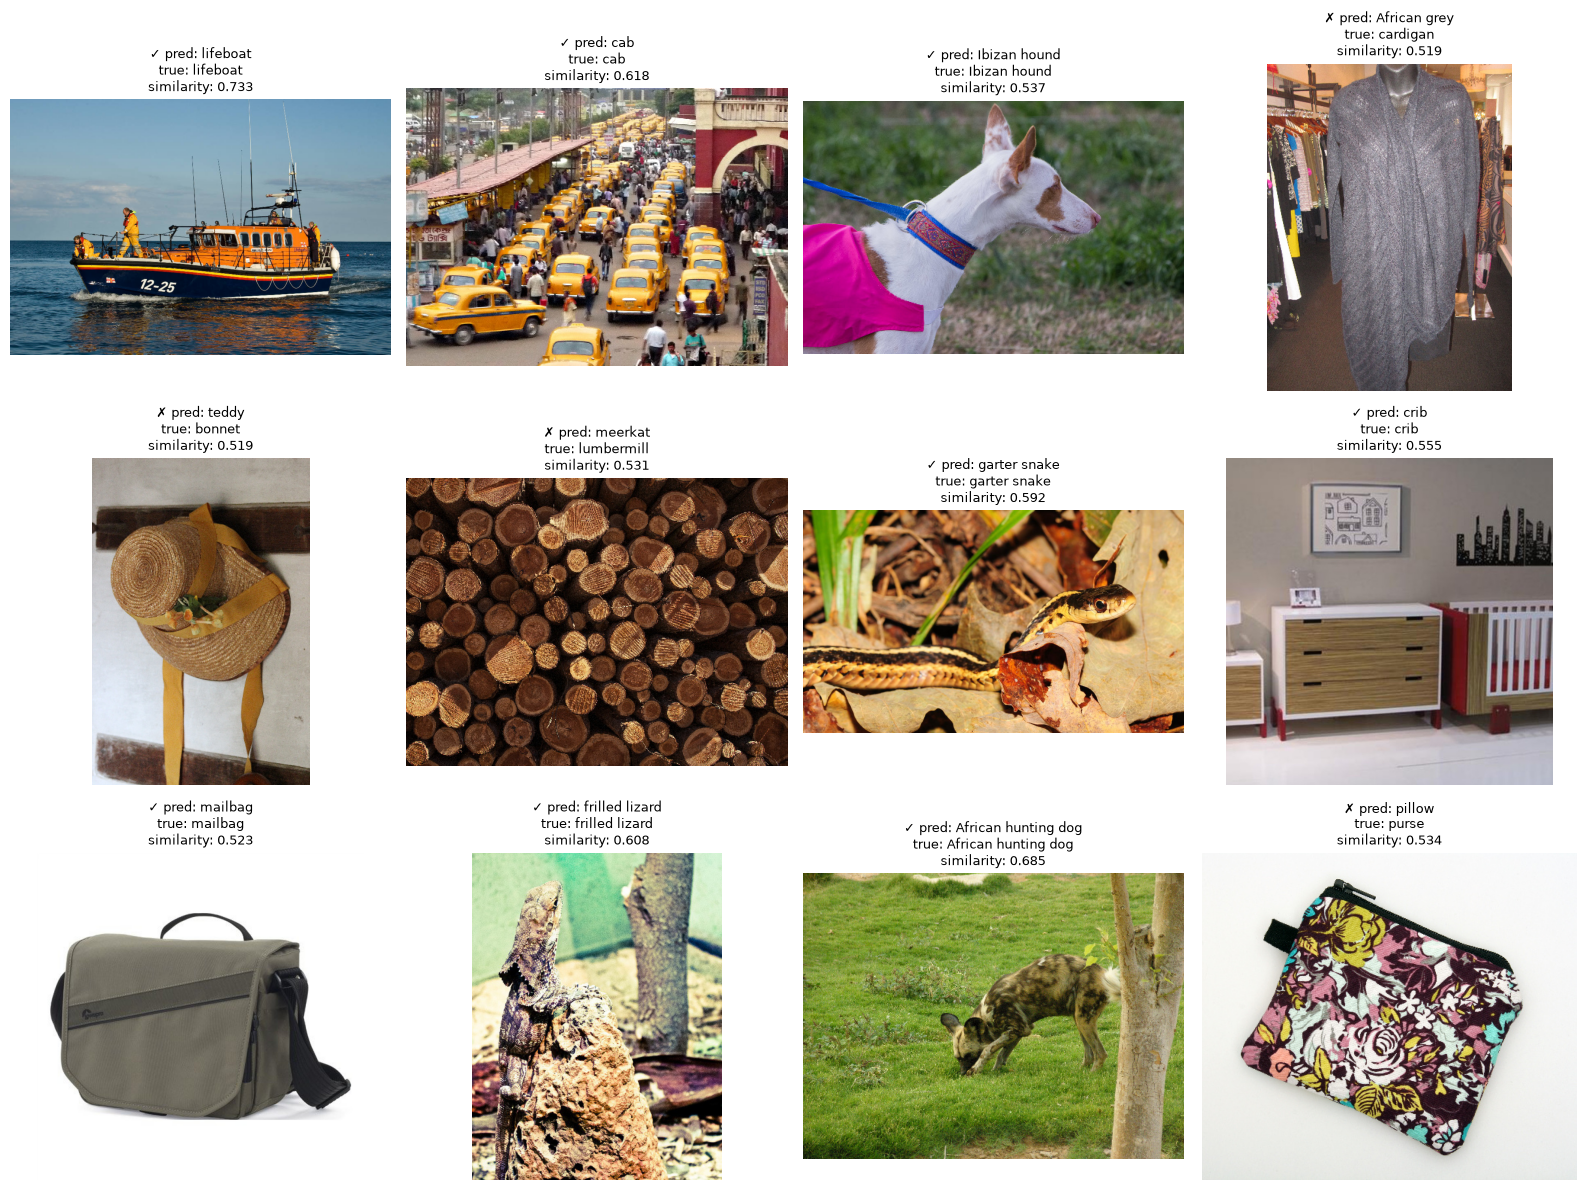

In [12]:
sample_count = min(NUM_EXAMPLES_TO_SHOW, len(predictions))
example_rows = predictions.sample(sample_count, random_state=RANDOM_SEED).reset_index(drop=True)
columns = PLOT_COLUMNS
rows = math.ceil(sample_count / columns)
figure, axes = plt.subplots(rows, columns, figsize=(16, 4 * rows))
axes = np.atleast_1d(axes).ravel()
for axis, (_, row) in zip(axes, example_rows.iterrows()):
    with Image.open(resolve_portable_image_path(row["image_path"])) as image:
        axis.imshow(image.convert("RGB"))
    mark = "✓" if row["correct_top1"] else "✗"
    axis.set_title(
        f"{mark} pred: {row['predicted_name']}\ntrue: {row['target_name']}\nsimilarity: {row['predicted_similarity']:.3f}",
        fontsize=9,
    )
    axis.axis("off")
for axis in axes[sample_count:]:
    axis.axis("off")
plt.tight_layout()
plt.show()


## 12. Classify one custom image (optional)

Set `CUSTOM_IMAGE_PATH` in the configuration cell, then rerun this cell.


In [13]:
@torch.inference_mode()
def classify_image(image_path, top_k=TOP_K):
    image_path = Path(image_path)
    with Image.open(image_path) as image:
        rgb_image = image.convert("RGB")
        tensor = EVAL_TRANSFORM(rgb_image).unsqueeze(0).to(DEVICE)
        with autocast_context():
            features = feature_extractor(tensor)
        scores = model.scores(features.float())[0]
        values, indices = scores.topk(top_k)
        result = pd.DataFrame({
            "class_idx": indices.cpu().tolist(),
            "class_name": [CLASS_NAMES[index] for index in indices.cpu().tolist()],
            "similarity": values.cpu().tolist(),
        })
        plt.figure(figsize=(6, 6))
        plt.imshow(rgb_image)
        plt.title(f"Top prediction: {result.iloc[0]['class_name']}")
        plt.axis("off")
        plt.show()
    return result

if CUSTOM_IMAGE_PATH is not None:
    display(classify_image(CUSTOM_IMAGE_PATH))
else:
    print("Set CUSTOM_IMAGE_PATH in the configuration cell to classify your own image.")


Set CUSTOM_IMAGE_PATH in the configuration cell to classify your own image.


## 13. Artifact summary

Keep `data/` and `artifacts/` beside the notebooks to reuse downloads, features, models, predictions, and metrics.


In [14]:
artifact_paths = [
    FEATURE_EXTRACTOR_PATH,
    *FEATURE_CACHE_PATHS.values(),
    MODEL_PATH,
    PREDICTIONS_PATH,
    PREDICTION_CACHE_PATH,
    METRICS_PATH,
    BENCHMARK_PATH,
]
artifact_rows = []
for path in artifact_paths:
    artifact_rows.append({
        "artifact": str(path),
        "exists": path.exists(),
        "size_mb": round(path.stat().st_size / 1024**2, 2) if path.is_file() else 0.0,
    })
display(pd.DataFrame(artifact_rows))


,artifact,exists,size_mb
0,/home/abbi/tamug_hdc_uav_v2/artifacts/resnet50...,True,97.80
1,/home/abbi/tamug_hdc_uav_v2/artifacts/features...,True,35.89
2,/home/abbi/tamug_hdc_uav_v2/artifacts/features...,True,6.69
3,/home/abbi/tamug_hdc_uav_v2/artifacts/features...,True,39.84
4,/home/abbi/tamug_hdc_uav_v2/artifacts/onlinehd...,True,116.33
5,/home/abbi/tamug_hdc_uav_v2/artifacts/predicti...,True,3.37
6,/home/abbi/tamug_hdc_uav_v2/artifacts/cache_on...,True,0.00
7,/home/abbi/tamug_hdc_uav_v2/artifacts/metrics_...,True,0.00
8,/home/abbi/tamug_hdc_uav_v2/artifacts/benchmar...,True,0.00
